# Building a structured dataset from manually reviewed links

The manual review identified 92 pages suitable for inclusion in the CSN project. This section scrapes those included pages, extracts relevant text, chunks the content and prepares the data for translation and structuring.

### 1. Load manually reviewed links

In [4]:
# Load required project dataset
# Required file:
# CSN_included_links_clean.csv

import pandas as pd
from pathlib import Path

DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")
FIGURE_DIR = Path("figures")

OUTPUT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)

included_links_path = Path("CSN_included_links_clean.csv")

included_links_df = pd.read_csv(included_links_path)

print(f"Included links loaded: {len(included_links_df):,}")
included_links_df.head()


Included links loaded: 92


,source_organisation,link_text,link_text_en,full_url,matched_topics,matched_keywords,review_decision,reviewed_topic_area,reviewer,review_notes
0,kanker.nl,Ga naar de Kanker Nazorg Wijzer,Go to the Cancer Aftercare Guide,https://www.kanker.nl/hulp-en-ondersteuning/ap...,additional_support,additional_support:support; additional_support...,Include,additional_support,Mos,NaN
1,kanker.nl,Vind hulp Vind hulp en ondersteuning tijdens e...,Find help Find help and support during and aft...,https://www.kanker.nl/hulp-en-ondersteuning/vi...,additional_support,additional_support:support; additional_support...,Include,additional_support,Mos,NaN
2,kanker.nl,Praktische hulp en steun,Practical help and support,https://www.kanker.nl/gevolgen-van-kanker/niet...,additional_support,additional_support:support; additional_support...,Include,additional_support,Mos,this one can also be referral process as it in...
3,zorgwijzer.nl,Wet maatschappelijke ondersteuning (Wmo),Social Support Act (Wmo),https://www.zorgwijzer.nl/faq/wmo,additional_support,additional_support:support; additional_support...,Include,additional_support,Mos,this one can also be referral process as it in...
4,kanker.nl,Voor jezelf zorgen (voor naasten) Leren om din...,Taking care of yourself (for loved ones) Learn...,https://www.kanker.nl/hulp-en-ondersteuning/ap...,additional_support,additional_support:support; additional_support...,Include,additional_support,Mos,it give an overview of Psychological care and ...


**Observation:** The input file contains **92 manually included links**, which become the starting point for scraping and structuring.


In [5]:
# reload local CSV and record scrape date
from datetime import date

input_path = Path("CSN_included_links_clean.csv")

included_links_df = pd.read_csv(input_path)

scrape_date = date.today().isoformat()

print(f"Included links loaded: {len(included_links_df):,}")
print(f"Scrape date: {scrape_date}")

included_links_df.head()


Included links loaded: 92
Scrape date: 2026-06-12


,source_organisation,link_text,link_text_en,full_url,matched_topics,matched_keywords,review_decision,reviewed_topic_area,reviewer,review_notes
0,kanker.nl,Ga naar de Kanker Nazorg Wijzer,Go to the Cancer Aftercare Guide,https://www.kanker.nl/hulp-en-ondersteuning/ap...,additional_support,additional_support:support; additional_support...,Include,additional_support,Mos,NaN
1,kanker.nl,Vind hulp Vind hulp en ondersteuning tijdens e...,Find help Find help and support during and aft...,https://www.kanker.nl/hulp-en-ondersteuning/vi...,additional_support,additional_support:support; additional_support...,Include,additional_support,Mos,NaN
2,kanker.nl,Praktische hulp en steun,Practical help and support,https://www.kanker.nl/gevolgen-van-kanker/niet...,additional_support,additional_support:support; additional_support...,Include,additional_support,Mos,this one can also be referral process as it in...
3,zorgwijzer.nl,Wet maatschappelijke ondersteuning (Wmo),Social Support Act (Wmo),https://www.zorgwijzer.nl/faq/wmo,additional_support,additional_support:support; additional_support...,Include,additional_support,Mos,this one can also be referral process as it in...
4,kanker.nl,Voor jezelf zorgen (voor naasten) Leren om din...,Taking care of yourself (for loved ones) Learn...,https://www.kanker.nl/hulp-en-ondersteuning/ap...,additional_support,additional_support:support; additional_support...,Include,additional_support,Mos,it give an overview of Psychological care and ...


### 2. Check required columns

In [6]:
# check that the input file has the fields needed downstream
required_columns = [
    "source_organisation",
    "full_url",
    "reviewed_topic_area",
]

missing_columns = [
    column for column in required_columns
    if column not in included_links_df.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

included_links_df = (
    included_links_df
    .dropna(subset=["full_url"])
    .drop_duplicates(subset=["full_url"])
    .reset_index(drop=True)
)

print(f"Unique included URLs: {len(included_links_df):,}")

Unique included URLs: 92


**Observation:** All **92 included links** are unique after the URL check, so no manually reviewed pages are removed at this stage.


File was checked to ensure it contained the fields needed for scraping and topic mapping. A duplicate check was also performed to esnure that each page is only scraped once.

### 3. Scrape page content

In [7]:
import time

import requests
from bs4 import BeautifulSoup


def scrape_page(url):
    """Scrape title and readable text from one webpage."""
    try:
        response = requests.get(url, timeout=15)
        response.raise_for_status()
    except requests.RequestException as error:
        return {
            "page_title_scraped": "",
            "raw_text": "",
            "scrape_status": "failed",
            "scrape_error": str(error),
        }

    soup = BeautifulSoup(response.text, "html.parser")

    for element in soup(["script", "style", "nav", "footer", "header"]):
        element.decompose()

    page_title = soup.title.get_text(" ", strip=True) if soup.title else ""
    raw_text = soup.get_text(" ", strip=True)

    return {
        "page_title_scraped": page_title,
        "raw_text": raw_text,
        "scrape_status": "success",
        "scrape_error": "",
    }

Page titles and readable text the pages was extract from each link with script, style, navigation, header and footer elements removed.

In [8]:
# scrape each included URL and collect page-level text
scraped_rows = []

for _, row in included_links_df.iterrows():
    scrape_result = scrape_page(row["full_url"])

    scraped_rows.append({
        **row.to_dict(),
        **scrape_result,
        "scrape_date": scrape_date,
    })

    time.sleep(1)

scraped_pages_df = pd.DataFrame(scraped_rows)

scraped_pages_df["scrape_status"].value_counts()

scrape_status
success    92
Name: count, dtype: int64

**Observation:** All **92 reviewed pages** were scraped successfully.


The scraper was applied to each link with a short delay used between requests to avoid placing unnecessary load on the source websites.

### 4. Clean scraped text

In [9]:
import re


def clean_text(text):
    """Clean whitespace from scraped text."""
    if pd.isna(text):
        return ""

    text = str(text)
    text = re.sub(r"\s+", " ", text)
    text = text.strip()

    return text


scraped_pages_df["clean_text"] = scraped_pages_df["raw_text"].map(clean_text)

scraped_pages_df[
    [
        "source_organisation",
        "full_url",
        "scrape_status",
        "page_title_scraped",
        "clean_text",
    ]
].head()

,source_organisation,full_url,scrape_status,page_title_scraped,clean_text
0,kanker.nl,https://www.kanker.nl/hulp-en-ondersteuning/ap...,success,Kanker Nazorg Wijzer | Kanker.nl,Kanker Nazorg Wijzer | Kanker.nl Overslaan en ...
1,kanker.nl,https://www.kanker.nl/hulp-en-ondersteuning/vi...,success,Vind hulp bij kanker | Kanker.nl,Vind hulp bij kanker | Kanker.nl Overslaan en ...
2,kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,success,Praktische hulp en steun | Kanker.nl,Praktische hulp en steun | Kanker.nl Overslaan...
3,zorgwijzer.nl,https://www.zorgwijzer.nl/faq/wmo,success,Wmo: betekenis en hulp bij aanvragen (+ info i...,Wmo: betekenis en hulp bij aanvragen (+ info i...
4,kanker.nl,https://www.kanker.nl/hulp-en-ondersteuning/ap...,success,Voor jezelf zorgen (voor naasten) | Kanker.nl,Voor jezelf zorgen (voor naasten) | Kanker.nl ...


The scraped text is now clean with repeated whitespace removed and spacing standardised.

### Check scrape quality

In [10]:
# measure scraped text length for quality checks
scraped_pages_df["text_length"] = (
    scraped_pages_df["clean_text"]
    .str.len()
)

scrape_quality_summary = (
    scraped_pages_df
    .groupby("scrape_status")
    .agg(
        pages=("full_url", "count"),
        median_text_length=("text_length", "median"),
        min_text_length=("text_length", "min"),
        max_text_length=("text_length", "max"),
    )
    .reset_index()
)

scrape_quality_summary

,scrape_status,pages,median_text_length,min_text_length,max_text_length
0,success,92,3734.5,669,17236


**Observation:** The scrape quality check shows all **92 pages** were successful, with a median cleaned text length of about **3,735 characters**.


Scrape quality was checked using scrape status and text length, with all pages were successfully scraped.

### 6. Chunk the cleaned text

In [11]:
# split long page text into sentence-based chunks
def split_into_chunks(text, max_words=120):
    """Split text into sentence-based chunks with a word limit."""
    if not text:
        return []

    sentences = re.split(r"(?<=[.!?])\s+", text)
    chunks = []
    current_chunk = []

    for sentence in sentences:
        sentence = sentence.strip()

        if not sentence:
            continue

        current_text = " ".join(current_chunk)
        current_word_count = len(current_text.split())
        sentence_word_count = len(sentence.split())

        if current_word_count + sentence_word_count <= max_words:
            current_chunk.append(sentence)
        else:
            chunk_text = " ".join(current_chunk).strip()

            if chunk_text:
                chunks.append(chunk_text)

            current_chunk = [sentence]

    final_chunk = " ".join(current_chunk).strip()

    if final_chunk:
        chunks.append(final_chunk)

    return chunks

In [12]:
# create traceable chunk records for each scraped page
chunk_rows = []

for page_index, row in scraped_pages_df.iterrows():
    chunks = split_into_chunks(row["clean_text"], max_words=120)

    for chunk_index, chunk_text in enumerate(chunks, start=1):
        chunk_rows.append({
            "source_organisation": row.get("source_organisation", ""),
            "source_page_title": row.get("page_title_scraped", ""),
            "source_url": row.get("full_url", ""),
            "scrape_date": row.get("scrape_date", ""),
            "reviewed_topic_area": row.get("reviewed_topic_area", ""),
            "chunk_id": f"page_{page_index + 1}_chunk_{chunk_index}",
            "chunk_number": chunk_index,
            "original_language": "Dutch",
            "original_text": chunk_text,
        })

chunks_df = pd.DataFrame(chunk_rows)

print(f"Created {len(chunks_df):,} chunks")

chunks_df.head()

Created 632 chunks


,source_organisation,source_page_title,source_url,scrape_date,reviewed_topic_area,chunk_id,chunk_number,original_language,original_text
0,kanker.nl,Kanker Nazorg Wijzer | Kanker.nl,https://www.kanker.nl/hulp-en-ondersteuning/ap...,2026-06-12,additional_support,page_1_chunk_1,1,Dutch,Kanker Nazorg Wijzer | Kanker.nl Overslaan en ...
1,kanker.nl,Kanker Nazorg Wijzer | Kanker.nl,https://www.kanker.nl/hulp-en-ondersteuning/ap...,2026-06-12,additional_support,page_1_chunk_2,2,Dutch,Je begint met het invullen van een vragenlijst...
2,kanker.nl,Kanker Nazorg Wijzer | Kanker.nl,https://www.kanker.nl/hulp-en-ondersteuning/ap...,2026-06-12,additional_support,page_1_chunk_3,3,Dutch,Meer informatie Deze module is ontwikkeld door...
3,kanker.nl,Kanker Nazorg Wijzer | Kanker.nl,https://www.kanker.nl/hulp-en-ondersteuning/ap...,2026-06-12,additional_support,page_1_chunk_4,4,Dutch,In de Appstore vind je zowel mobiele apps voor...
4,kanker.nl,Kanker Nazorg Wijzer | Kanker.nl,https://www.kanker.nl/hulp-en-ondersteuning/ap...,2026-06-12,additional_support,page_1_chunk_5,5,Dutch,"€ 24,95 Kom in beweging Met deze module kijk j..."


**Observation:** The scraped page text was split into **632 chunks**, creating smaller units for topic matching and translation.


The cleaned text was split into sentence based chunks, with each chunk keeping it source URL and scrape date for traceability.

Chunking was used because individual pages may contain several pieces of information relevant to different patient navigation questions.

### 7. Classify chunks by content

In [13]:
import re
import unicodedata

import pandas as pd


def normalize_text(value):
    """Return lower-case text with accents and repeated spaces removed."""
    if pd.isna(value):
        return ""

    text = unicodedata.normalize("NFKD", str(value))
    text = "".join(char for char in text if not unicodedata.combining(char))
    text = text.lower()

    return re.sub(r"\s+", " ", text).strip()


def keyword_pattern(keyword):
    """Create a regex pattern for matching a keyword or phrase."""
    escaped = re.escape(normalize_text(keyword))

    # Match phrases across spaces, hyphens, slashes and underscores.
    escaped = escaped.replace(r"\ ", r"[\s_\-/]+")

    return re.compile(rf"(?<![a-z0-9]){escaped}(?![a-z0-9])")

In [14]:
# keyword map used for content-based chunk classification
topic_keyword_map = {
    "referrals_process": [
        "referral", "referrals", "refer", "referred", "referring",
        "referral process", "care pathway", "patient pathway",
        "general practitioner", "gp", "specialist referral",
        "hospital referral", "choose hospital", "choose specialist",
        "change doctor", "verwijzing", "verwijzingen", "verwijsbrief",
        "doorverwijzing", "doorverwijzen", "huisarts", "specialist",
        "ziekenhuis kiezen", "specialist kiezen", "arts kiezen",
        "vrije artsenkeuze", "wisselen van arts", "zorgpad",
        "zorgtraject", "patientroute",
    ],
    "waiting_times": [
        "waiting time", "waiting times", "waiting list", "wait time",
        "appointment delay", "treatment delay", "delay in care",
        "wachtlijst", "wachtlijsten", "wachttijd", "wachttijden",
        "te lang wachten", "vertraging", "doorlooptijd",
        "toegangstijd", "treeknorm", "treeknormen",
        "zorgbemiddeling", "wachtlijstbemiddeling", "zorgplicht",
    ],
    "treatment_decisions": [
        "treatment decision", "treatment decisions", "treatment choice",
        "treatment options", "treatment plan", "shared decision",
        "shared decision making", "decision aid", "decision support",
        "choose treatment", "benefits and risks", "side effects",
        "pros and cons", "behandelkeuze", "behandelbeslissing",
        "samen beslissen", "gedeelde besluitvorming", "keuzehulp",
        "beslissingshulp", "behandelopties", "behandelplan",
        "voor- en nadelen", "bijwerkingen",
    ],
    "second_opinions": [
        "second opinion", "second opinions", "request second opinion",
        "right to second opinion", "second opinion abroad",
        "independent opinion", "another opinion", "insurance second opinion",
        "covered by insurance", "tweede mening", "recht op second opinion",
        "second opinion aanvragen", "second opinion buitenland",
        "vergoeding second opinion", "zorgverzekering second opinion",
        "zorgverzekeraar second opinion", "ander oordeel",
        "onafhankelijk oordeel", "deskundig oordeel", "andere arts",
        "andere specialist",
    ],
    "additional_support": [
        "support", "additional support", "practical support",
        "psychological support", "emotional support", "social support",
        "peer support", "support group", "aftercare", "survivorship",
        "rehabilitation", "financial support", "work and cancer",
        "family support", "carer", "caregiver", "palliative care",
        "home care", "physiotherapy", "nutrition advice",
        "fertility support", "ondersteuning", "praktische hulp",
        "psychologische hulp", "emotionele steun", "lotgenoten",
        "nazorg", "revalidatie", "financiele hulp", "werk en kanker",
        "mantelzorg", "naasten", "palliatieve zorg", "thuiszorg",
        "fysiotherapie", "voedingsadvies", "vruchtbaarheid",
    ],
    "communication_understanding": [
        "communication", "communicate", "understand", "understanding",
        "explanation", "explain", "plain language", "simple explanation",
        "medical terminology", "medical terms", "interpreter",
        "translation", "translator", "questions to ask", "ask questions",
        "consultation", "conversation with doctor", "health literacy",
        "communicatie", "communiceren", "begrijpen", "uitleg",
        "toelichting", "duidelijke taal", "begrijpelijke taal",
        "medische termen", "tolk", "vertaling", "vertaler",
        "vragen stellen", "vragen aan arts", "gesprek met arts",
        "consult", "spreekuur", "gezondheidsvaardigheden",
    ],
}


topic_patterns = {
    topic: [(keyword, keyword_pattern(keyword)) for keyword in keywords]
    for topic, keywords in topic_keyword_map.items()
}


def match_chunk_topics(text):
    """Assign CSN topic areas based on the chunk text itself."""
    text_norm = normalize_text(text)
    matched_topics = []

    for topic, patterns in topic_patterns.items():
        topic_has_match = any(
            pattern.search(text_norm) for _, pattern in patterns
        )

        if topic_has_match:
            matched_topics.append(topic)

    return "; ".join(matched_topics)


chunks_df["chunk_topic_area"] = (
    chunks_df["original_text"]
    .map(match_chunk_topics)
)

chunks_df["chunk_topic_area"].value_counts()

chunk_topic_area
                                                                       217
additional_support                                                     207
referrals_process                                                       56
treatment_decisions                                                     50
referrals_process; additional_support                                   40
communication_understanding                                             16
treatment_decisions; additional_support                                 16
additional_support; communication_understanding                         10
referrals_process; communication_understanding                          10
referrals_process; treatment_decisions                                   3
waiting_times; additional_support                                        2
referrals_process; treatment_decisions; communication_understanding      2
waiting_times; additional_support; communication_understanding           1
referral

**Observation:** Topic keyword matching retained **415 matched chunks** and separated **217 unmatched chunks** for auditability.


Each text chunk was classified using keyword matching on the chunk’s own content, as one webpage may contain information relevant to more than one CSN topic area.

Unmatched chunks were not automatically assigned a topic, as an individual chunk should only be included in the main Patient Navigator dataset if the chunk itself contains evidence of a relevant CSN topic.

This topic matching identified 415 chunks that matched at least one CSN topic area. The remaining 217 chunks did not contain the selected topic keywords.

The unmatched chunks were therefore separated for possible future review, while the 415 matched chunks were carried forward into the main structured dataset.

Some chunks matched more than one topic area, which is why the topic-instance total is higher than the number of matched chunks. This supports the decision to classify chunks based on their own content rather than relying only on the page-level manual review topic.

### 8. Separate matched and unmatched chunks

In [15]:
# assign topic labels to each chunk from matched keywords
chunks_df["chunk_topic_area"] = (
    chunks_df["chunk_topic_area"]
    .fillna("")
    .astype(str)
)

has_chunk_topic = (
    chunks_df["chunk_topic_area"]
    .str.strip()
    .ne("")
)

matched_chunks_df = (
    chunks_df
    .loc[has_chunk_topic]
    .copy()
    .reset_index(drop=True)
)

unmatched_chunks_df = (
    chunks_df
    .loc[~has_chunk_topic]
    .copy()
    .reset_index(drop=True)
)

print(f"Total chunks: {len(chunks_df):,}")
print(f"Matched chunks retained: {len(matched_chunks_df):,}")
print(f"Unmatched chunks separated: {len(unmatched_chunks_df):,}")

Total chunks: 632
Matched chunks retained: 415
Unmatched chunks separated: 217


### 9. Map chunks to community questions

In [16]:
# map each topic area to a patient-facing question
community_question_map = {
    "referrals_process": (
        "How do referrals work in the Netherlands? | "
        "Can I choose my hospital or specialist? | "
        "Can I change doctors?"
    ),
    "waiting_times": (
        "How long should I expect to wait for appointments or treatment? | "
        "What can I do if I feel the process is too slow? | "
        "Is it normal to wait between steps?"
    ),
    "treatment_decisions": (
        "How are treatment decisions made? | "
        "Can I ask for alternative options? | "
        "Do I have time to decide?"
    ),
    "second_opinions": (
        "Am I allowed to get a second opinion, including in another country? | "
        "How do I request one? | "
        "Will it be covered by insurance?"
    ),
    "additional_support": (
        "What additional services can I access? | "
        "How can I access psychological care, physiotherapy, nutrition advice "
        "or fertility support? | "
        "How do I get referred to these services?"
    ),
    "communication_understanding": (
        "What if I do not understand medical terminology? | "
        "Can I request explanations in simpler language? | "
        "Are there English-speaking healthcare providers?"
    ),
}


def split_topic_values(topic_string):
    """Split semi-colon separated topic labels into a clean list."""
    if pd.isna(topic_string):
        return []

    topics = []

    for topic in str(topic_string).split(";"):
        topic = topic.strip()

        if topic:
            topics.append(topic)

    return topics


def assign_community_questions(topic_string):
    """Assign community questions from content-based topic labels."""
    questions = []

    for topic in split_topic_values(topic_string):
        question = community_question_map.get(topic)

        if question and question not in questions:
            questions.append(question)

    return " | ".join(questions)


matched_chunks_df["final_topic_area"] = matched_chunks_df["chunk_topic_area"]

matched_chunks_df["community_question"] = (
    matched_chunks_df["final_topic_area"]
    .map(assign_community_questions)
)

matched_chunks_df[
    [
        "reviewed_topic_area",
        "chunk_topic_area",
        "final_topic_area",
        "community_question",
        "original_text",
    ]
].head()

,reviewed_topic_area,chunk_topic_area,final_topic_area,community_question,original_text
0,additional_support,additional_support,additional_support,What additional services can I access? | How c...,Kanker Nazorg Wijzer | Kanker.nl Overslaan en ...
1,additional_support,additional_support,additional_support,What additional services can I access? | How c...,Meer informatie Deze module is ontwikkeld door...
2,additional_support,additional_support,additional_support,What additional services can I access? | How c...,Afbeelding Vind hulp Titel Dagelijks leven Bek...
3,additional_support,additional_support,additional_support,What additional services can I access? | How c...,Praktische hulp en steun | Kanker.nl Overslaan...
4,additional_support,referrals_process; additional_support,referrals_process; additional_support,How do referrals work in the Netherlands? | Ca...,Huisarts en wijkverpleegkundige Is je naaste t...


Community questions were assigned from the content based chunk topic, with the manually reviewed page topic retained as context.

### 10. Translation and source tracing fields

In [17]:
# add placeholder fields for translation and review
matched_chunks_df["english_translation"] = ""
matched_chunks_df["summary_or_answer"] = ""
matched_chunks_df["next_step"] = ""

matched_chunks_df["topic_assignment_method"] = "content_keyword_match"
matched_chunks_df["needs_csn_review"] = True
matched_chunks_df["final_review_notes"] = ""

matched_chunks_df["source_trace"] = (
    matched_chunks_df["source_organisation"].astype(str)
    + " | "
    + matched_chunks_df["source_url"].astype(str)
    + " | scraped "
    + matched_chunks_df["scrape_date"].astype(str)
)

unmatched_chunks_df["topic_assignment_method"] = "no_content_keyword_match"
unmatched_chunks_df["needs_csn_review"] = True
unmatched_chunks_df["final_review_notes"] = (
    "No content-based topic match. Kept separately for future review."
)

unmatched_chunks_df["source_trace"] = (
    unmatched_chunks_df["source_organisation"].astype(str)
    + " | "
    + unmatched_chunks_df["source_url"].astype(str)
    + " | scraped "
    + unmatched_chunks_df["scrape_date"].astype(str)
)

Additional fields were added for translation, future summary writing, review status and source tracing.

The unmatched chunks were not discarded entirely. They were kept in a separate dataset for possible future review, but they were not included in the main Patient Navigator dataset at this stage.

### 11. Create the main structured dataset

In [18]:
# organise the final structured dataset
output_columns = [
    "source_organisation",
    "source_page_title",
    "source_url",
    "scrape_date",
    "reviewed_topic_area",
    "chunk_topic_area",
    "community_question",
    "chunk_id",
    "chunk_number",
    "original_language",
    "original_text",
    "english_translation",
    "next_step",
    "topic_assignment_method",
    "source_trace",
]

for column in output_columns:
    if column not in matched_chunks_df.columns:
        matched_chunks_df[column] = ""

structured_chunked_dataset_df = matched_chunks_df[output_columns].copy()

print(f"Main structured dataset rows: {len(structured_chunked_dataset_df):,}")
print(f"Unmatched chunks kept separately: {len(unmatched_chunks_df):,}")

structured_chunked_dataset_df.head()

Main structured dataset rows: 415
Unmatched chunks kept separately: 217


,source_organisation,source_page_title,source_url,scrape_date,reviewed_topic_area,chunk_topic_area,community_question,chunk_id,chunk_number,original_language,original_text,english_translation,next_step,topic_assignment_method,source_trace
0,kanker.nl,Kanker Nazorg Wijzer | Kanker.nl,https://www.kanker.nl/hulp-en-ondersteuning/ap...,2026-06-12,additional_support,additional_support,What additional services can I access? | How c...,page_1_chunk_1,1,Dutch,Kanker Nazorg Wijzer | Kanker.nl Overslaan en ...,,,content_keyword_match,kanker.nl | https://www.kanker.nl/hulp-en-onde...
1,kanker.nl,Kanker Nazorg Wijzer | Kanker.nl,https://www.kanker.nl/hulp-en-ondersteuning/ap...,2026-06-12,additional_support,additional_support,What additional services can I access? | How c...,page_1_chunk_3,3,Dutch,Meer informatie Deze module is ontwikkeld door...,,,content_keyword_match,kanker.nl | https://www.kanker.nl/hulp-en-onde...
2,kanker.nl,Vind hulp bij kanker | Kanker.nl,https://www.kanker.nl/hulp-en-ondersteuning/vi...,2026-06-12,additional_support,additional_support,What additional services can I access? | How c...,page_2_chunk_2,2,Dutch,Afbeelding Vind hulp Titel Dagelijks leven Bek...,,,content_keyword_match,kanker.nl | https://www.kanker.nl/hulp-en-onde...
3,kanker.nl,Praktische hulp en steun | Kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,2026-06-12,additional_support,additional_support,What additional services can I access? | How c...,page_3_chunk_1,1,Dutch,Praktische hulp en steun | Kanker.nl Overslaan...,,,content_keyword_match,kanker.nl | https://www.kanker.nl/gevolgen-van...
4,kanker.nl,Praktische hulp en steun | Kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,2026-06-12,additional_support,referrals_process; additional_support,How do referrals work in the Netherlands? | Ca...,page_3_chunk_2,2,Dutch,Huisarts en wijkverpleegkundige Is je naaste t...,,,content_keyword_match,kanker.nl | https://www.kanker.nl/gevolgen-van...


**Observation:** The first structured dataset contains **415 matched chunks** before cleaning for translation.


### 12. Analysis

In [19]:
import matplotlib.pyplot as plt
import pandas as pd


# Each chunk can match more than one topic area.
# This separates semi-colon separated topic labels so that each topic
# instance is counted individually.
topic_instances_df = (
    matched_chunks_df
    .assign(
        topic_instance=matched_chunks_df["chunk_topic_area"]
        .fillna("")
        .str.split(";")
    )
    .explode("topic_instance")
)

topic_instances_df["topic_instance"] = (
    topic_instances_df["topic_instance"]
    .str.strip()
)

topic_instances_df = (
    topic_instances_df
    .loc[lambda df: df["topic_instance"].ne("")]
)

# Create a cleaner display label for the chart.
topic_label_map = {
    "additional_support": "Additional support",
    "referrals_process": "Referrals/process",
    "treatment_decisions": "Treatment decisions",
    "communication_understanding": "Communication/understanding",
    "waiting_times": "Waiting times",
    "second_opinions": "Second opinions",
}

topic_counts = (
    topic_instances_df["topic_instance"]
    .value_counts()
    .rename_axis("topic_area")
    .reset_index(name="topic_instances")
)

topic_counts["topic_label"] = (
    topic_counts["topic_area"]
    .map(topic_label_map)
    .fillna(topic_counts["topic_area"])
)

topic_counts = topic_counts.sort_values(
    by="topic_instances",
    ascending=True
)

topic_counts

,topic_area,topic_instances,topic_label
4,waiting_times,3,Waiting times
3,communication_understanding,40,Communication/understanding
2,treatment_decisions,72,Treatment decisions
1,referrals_process,113,Referrals/process
0,additional_support,278,Additional support


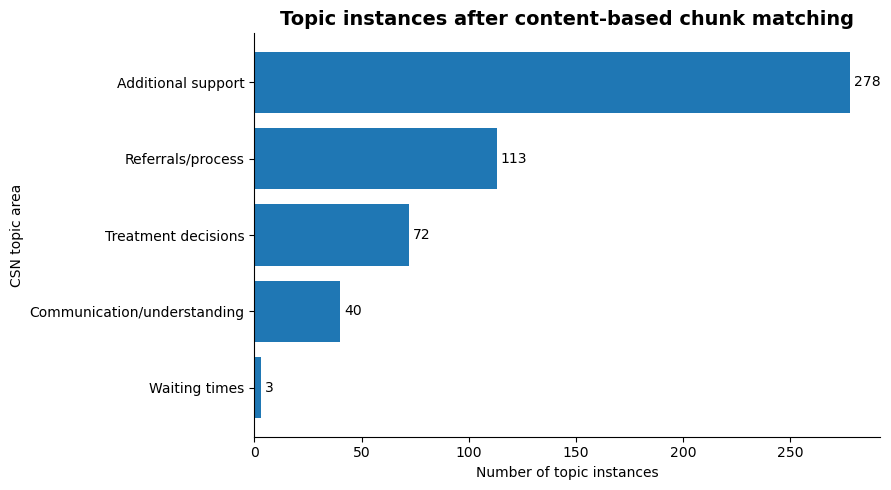

In [20]:
# Plot topic instances as a horizontal bar chart.

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    topic_counts["topic_label"],
    topic_counts["topic_instances"]
)

ax.set_title(
    "Topic instances after content-based chunk matching",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Number of topic instances")
ax.set_ylabel("CSN topic area")

# Add count labels to the end of each bar.
for index, value in enumerate(topic_counts["topic_instances"]):
    ax.text(
        value + 2,
        index,
        str(value),
        va="center",
        fontsize=10
    )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### Summary

A matched structured DataFrame has now been created using only chunks that contained content evidence of at least one CSN topic area, with unmatched chunks separated for possible future review.

The original chunking process created 632 chunks from the manually reviewed links. Of these, 415 chunks matched at least one CSN topic area and were carried forward into the main structured dataset. The remaining 217 chunks did not contain the selected topic keywords and were kept separate.

The matched dataset contains 415 chunks from 91 unique source URLs. Although 92 included links were taken into the scraping stage, one source page did not contribute any matched chunks to the main structured dataset.

Source coverage remained heavily weighted towards kanker.nl.

Using the content-based chunk matching, the topic instances were:

- Additional support: 278
- Referrals/process: 113
- Treatment decisions: 72
- Communication and understanding: 40
- Waiting times: 3
- Second opinions: 1

Some chunks matched more than one topic area, which is why the topic-instance total is higher than the number of rows.

Overall, the matched dataset is smaller than the original chunked dataset, but it is more conservative and better aligned with the Patient Navigator aim. Coverage is still uneven, with additional support, referrals/process and treatment decisions much better represented than waiting times and second opinions.

# Cleaning and preparing chunks for translation

The previous section created a matched chunk dataset, where only chunks that matched at least one CSN topic area based on their own content were retained in the main dataset.

Before translation, these chunks need to be checked and cleaned.

### 1. Create a copy of the dataset

In [21]:
# work on a copy so the original structured dataset is preserved
chunks_cleaning_df = structured_chunked_dataset_df.copy()

print(f"Starting chunks: {len(chunks_cleaning_df):,}")

chunks_cleaning_df.head()

Starting chunks: 415


,source_organisation,source_page_title,source_url,scrape_date,reviewed_topic_area,chunk_topic_area,community_question,chunk_id,chunk_number,original_language,original_text,english_translation,next_step,topic_assignment_method,source_trace
0,kanker.nl,Kanker Nazorg Wijzer | Kanker.nl,https://www.kanker.nl/hulp-en-ondersteuning/ap...,2026-06-12,additional_support,additional_support,What additional services can I access? | How c...,page_1_chunk_1,1,Dutch,Kanker Nazorg Wijzer | Kanker.nl Overslaan en ...,,,content_keyword_match,kanker.nl | https://www.kanker.nl/hulp-en-onde...
1,kanker.nl,Kanker Nazorg Wijzer | Kanker.nl,https://www.kanker.nl/hulp-en-ondersteuning/ap...,2026-06-12,additional_support,additional_support,What additional services can I access? | How c...,page_1_chunk_3,3,Dutch,Meer informatie Deze module is ontwikkeld door...,,,content_keyword_match,kanker.nl | https://www.kanker.nl/hulp-en-onde...
2,kanker.nl,Vind hulp bij kanker | Kanker.nl,https://www.kanker.nl/hulp-en-ondersteuning/vi...,2026-06-12,additional_support,additional_support,What additional services can I access? | How c...,page_2_chunk_2,2,Dutch,Afbeelding Vind hulp Titel Dagelijks leven Bek...,,,content_keyword_match,kanker.nl | https://www.kanker.nl/hulp-en-onde...
3,kanker.nl,Praktische hulp en steun | Kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,2026-06-12,additional_support,additional_support,What additional services can I access? | How c...,page_3_chunk_1,1,Dutch,Praktische hulp en steun | Kanker.nl Overslaan...,,,content_keyword_match,kanker.nl | https://www.kanker.nl/gevolgen-van...
4,kanker.nl,Praktische hulp en steun | Kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,2026-06-12,additional_support,referrals_process; additional_support,How do referrals work in the Netherlands? | Ca...,page_3_chunk_2,2,Dutch,Huisarts en wijkverpleegkundige Is je naaste t...,,,content_keyword_match,kanker.nl | https://www.kanker.nl/gevolgen-van...


A working copy of the dataset was created so cleaning could be done without changing the original structured dataset.

### 2. Basic text quality checks

In [22]:
# add word and character counts for each chunk

chunks_cleaning_df["original_text"] = (
    chunks_cleaning_df["original_text"]
    .fillna("")
    .astype(str)
)

chunks_cleaning_df["word_count"] = (
    chunks_cleaning_df["original_text"]
    .str.split()
    .str.len()
)

chunks_cleaning_df["character_count"] = (
    chunks_cleaning_df["original_text"]
    .str.len()
)

chunks_cleaning_df[
    [
        "chunk_id",
        "source_organisation",
        "chunk_topic_area",
        "word_count",
        "character_count",
        "original_text",
    ]
].head()

,chunk_id,source_organisation,chunk_topic_area,word_count,character_count,original_text
0,page_1_chunk_1,kanker.nl,additional_support,113,697,Kanker Nazorg Wijzer | Kanker.nl Overslaan en ...
1,page_1_chunk_3,kanker.nl,additional_support,114,688,Meer informatie Deze module is ontwikkeld door...
2,page_2_chunk_2,kanker.nl,additional_support,109,747,Afbeelding Vind hulp Titel Dagelijks leven Bek...
3,page_3_chunk_1,kanker.nl,additional_support,112,741,Praktische hulp en steun | Kanker.nl Overslaan...
4,page_3_chunk_2,kanker.nl,referrals_process; additional_support,114,793,Huisarts en wijkverpleegkundige Is je naaste t...


To identify chunks that are too short to contain useful information related to patient navigation, word count and character count for each chunk was calculated.

### 3. Flag very short chunks

In [23]:
# flag chunks too short to be useful for translation
minimum_word_count = 20

chunks_cleaning_df["is_very_short"] = (
    chunks_cleaning_df["word_count"] < minimum_word_count
)

chunks_cleaning_df["is_very_short"].value_counts()

is_very_short
False    413
True       2
Name: count, dtype: int64

**Observation:** Only **2 chunks** are below the 20-word threshold, so very short text is a minor issue.


In [24]:
# inspect chunks below the word-count threshold
short_chunks_df = (
    chunks_cleaning_df
    .loc[lambda df: df["is_very_short"]]
    [
        [
            "chunk_id",
            "source_organisation",
            "source_url",
            "word_count",
            "original_text",
        ]
    ]
)

short_chunks_df

,chunk_id,source_organisation,source_url,word_count,original_text
40,page_11_chunk_4,nfk.nl,https://nfk.nl/middelen/producten/overzichtska...,11,Bekijk de Overzichtskaart werk en kanker Meer ...
229,page_44_chunk_6,iknl.nl,https://iknl.nl/kankersoorten/baarmoederkanker...,19,Op Pallialine vindt u richtlijnen over symptoo...


Only two matched chunks contained fewer than 20 words.

From manual inspection, it appeared these short chunks mainly contained signposting text, such as links to work-and-cancer resources, information about Pallialine and guidelines it offers, and support services for serious illness. Because this information could still be useful for the Patient Navigation, they were not removed.

### 4. Flag duplicated chunk text

In [25]:
# normalise text so duplicate chunks can be detected
chunks_cleaning_df["normalised_chunk_text"] = (
    chunks_cleaning_df["original_text"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

chunks_cleaning_df["is_duplicate_text"] = (
    chunks_cleaning_df
    .duplicated(subset=["normalised_chunk_text"], keep="first")
)

chunks_cleaning_df["is_duplicate_text"].value_counts()

is_duplicate_text
False    388
True      27
Name: count, dtype: int64

**Observation:** **27 duplicated chunks** were identified through normalised text matching.


In [26]:
# inspect duplicated chunks before removing them
duplicate_chunks_df = (
    chunks_cleaning_df
    .loc[lambda df: df["is_duplicate_text"]]
    [
        [
            "chunk_id",
            "source_organisation",
            "source_url",
            "word_count",
            "original_text",
        ]
    ]
)

duplicate_chunks_df

,chunk_id,source_organisation,source_url,word_count,original_text
65,page_15_chunk_1,kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,115,Wat is palliatieve zorg? | Kanker.nl Overslaan...
66,page_15_chunk_2,kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,115,Palliatieve zorg is niet hetzelfde als palliat...
67,page_15_chunk_3,kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,104,Mensen denken vaak dat palliatieve zorg alleen...
68,page_15_chunk_4,kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,114,Palliatieve zorg richt zich op alles wat belan...
69,page_15_chunk_5,kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,115,Je kunt zelf ook beslissen of je een behandeli...
70,page_15_chunk_6,kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,119,Lees meer over psychosociale zorg bij ongenees...
71,page_15_chunk_7,kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,101,Nazorg Na de dood van een dierbare gaat het le...
72,page_15_chunk_8,kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,111,De palliatieve zorg wordt (voor een deel) beta...
73,page_15_chunk_9,kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,116,Het kan gaan om: medisch specialist verpleegku...
74,page_15_chunk_10,kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,113,Lees verder op andere websites (5) Over pallia...


27 duplicate chunks were identified by normalising the chunk text and checking for repeats. The first occurrence of each duplicated chunk was kept, while later duplicates were flagged for removal before translation.

### 5. Create final exclusion flag

In [27]:
# combine cleaning flags into one exclusion field
chunks_cleaning_df["exclude_before_translation"] = (
    chunks_cleaning_df["is_duplicate_text"]
)

chunks_cleaning_df["exclude_before_translation"].value_counts()

exclude_before_translation
False    388
True      27
Name: count, dtype: int64

**Observation:** The final exclusion flag removes **27 chunks**, all due to duplication rather than short length.


In [28]:
# keep excluded chunks for auditability
excluded_chunks_df = (
    chunks_cleaning_df
    .loc[lambda df: df["exclude_before_translation"]]
    [
        [
            "chunk_id",
            "source_organisation",
            "source_url",
            "word_count",
            "is_duplicate_text",
            "original_text",
        ]
    ]
)

excluded_chunks_df.head(20)

,chunk_id,source_organisation,source_url,word_count,is_duplicate_text,original_text
65,page_15_chunk_1,kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,115,True,Wat is palliatieve zorg? | Kanker.nl Overslaan...
66,page_15_chunk_2,kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,115,True,Palliatieve zorg is niet hetzelfde als palliat...
67,page_15_chunk_3,kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,104,True,Mensen denken vaak dat palliatieve zorg alleen...
68,page_15_chunk_4,kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,114,True,Palliatieve zorg richt zich op alles wat belan...
69,page_15_chunk_5,kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,115,True,Je kunt zelf ook beslissen of je een behandeli...
70,page_15_chunk_6,kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,119,True,Lees meer over psychosociale zorg bij ongenees...
71,page_15_chunk_7,kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,101,True,Nazorg Na de dood van een dierbare gaat het le...
72,page_15_chunk_8,kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,111,True,De palliatieve zorg wordt (voor een deel) beta...
73,page_15_chunk_9,kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,116,True,Het kan gaan om: medisch specialist verpleegku...
74,page_15_chunk_10,kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,113,True,Lees verder op andere websites (5) Over pallia...


The final exclusion flag removed 27 duplicated chunks before translation.

### 6. Create cleaned dataset for translation

In [29]:
# retain only useful matched chunks for translation
chunks_for_translation_df = (
    chunks_cleaning_df
    .loc[lambda df: ~df["exclude_before_translation"]]
    .drop(
        columns=[
            "normalised_chunk_text",
        ],
        errors="ignore",
    )
    .reset_index(drop=True)
)

print(f"Matched chunks before cleaning: {len(chunks_cleaning_df):,}")
print(f"Chunks retained for translation: {len(chunks_for_translation_df):,}")
print(
    "Chunks removed before translation: "
    f"{len(chunks_cleaning_df) - len(chunks_for_translation_df):,}"
)

chunks_for_translation_df.head()

Matched chunks before cleaning: 415
Chunks retained for translation: 388
Chunks removed before translation: 27


,source_organisation,source_page_title,source_url,scrape_date,reviewed_topic_area,chunk_topic_area,community_question,chunk_id,chunk_number,original_language,original_text,english_translation,next_step,topic_assignment_method,source_trace,word_count,character_count,is_very_short,is_duplicate_text,exclude_before_translation
0,kanker.nl,Kanker Nazorg Wijzer | Kanker.nl,https://www.kanker.nl/hulp-en-ondersteuning/ap...,2026-06-12,additional_support,additional_support,What additional services can I access? | How c...,page_1_chunk_1,1,Dutch,Kanker Nazorg Wijzer | Kanker.nl Overslaan en ...,,,content_keyword_match,kanker.nl | https://www.kanker.nl/hulp-en-onde...,113,697,False,False,False
1,kanker.nl,Kanker Nazorg Wijzer | Kanker.nl,https://www.kanker.nl/hulp-en-ondersteuning/ap...,2026-06-12,additional_support,additional_support,What additional services can I access? | How c...,page_1_chunk_3,3,Dutch,Meer informatie Deze module is ontwikkeld door...,,,content_keyword_match,kanker.nl | https://www.kanker.nl/hulp-en-onde...,114,688,False,False,False
2,kanker.nl,Vind hulp bij kanker | Kanker.nl,https://www.kanker.nl/hulp-en-ondersteuning/vi...,2026-06-12,additional_support,additional_support,What additional services can I access? | How c...,page_2_chunk_2,2,Dutch,Afbeelding Vind hulp Titel Dagelijks leven Bek...,,,content_keyword_match,kanker.nl | https://www.kanker.nl/hulp-en-onde...,109,747,False,False,False
3,kanker.nl,Praktische hulp en steun | Kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,2026-06-12,additional_support,additional_support,What additional services can I access? | How c...,page_3_chunk_1,1,Dutch,Praktische hulp en steun | Kanker.nl Overslaan...,,,content_keyword_match,kanker.nl | https://www.kanker.nl/gevolgen-van...,112,741,False,False,False
4,kanker.nl,Praktische hulp en steun | Kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,2026-06-12,additional_support,referrals_process; additional_support,How do referrals work in the Netherlands? | Ca...,page_3_chunk_2,2,Dutch,Huisarts en wijkverpleegkundige Is je naaste t...,,,content_keyword_match,kanker.nl | https://www.kanker.nl/gevolgen-van...,114,793,False,False,False


**Observation:** Cleaning reduces the matched chunks from **415** to **388** chunks prepared for translation.


### 8. Cleaning results

In [30]:
# summarise the cleaning decisions before export
cleaning_summary = pd.DataFrame({
    "metric": [
        "Matched chunks before cleaning",
        "Very short chunks inspected",
        "Duplicated chunks removed",
        "Excluded before translation",
        "Chunks retained for translation",
    ],
    "count": [
        len(chunks_cleaning_df),
        chunks_cleaning_df["is_very_short"].sum(),
        chunks_cleaning_df["is_duplicate_text"].sum(),
        chunks_cleaning_df["exclude_before_translation"].sum(),
        len(chunks_for_translation_df),
    ],
})

cleaning_summary

,metric,count
0,Matched chunks before cleaning,415
1,Very short chunks inspected,2
2,Duplicated chunks removed,27
3,Excluded before translation,27
4,Chunks retained for translation,388


The cleaning process reduced the matched chunk dataset from 415 chunks to 388 chunks for translation, with 27 chunks removed before translation.

The removed chunks were duplicated text. On inspection, these duplicates mainly came from repeated source content appearing across similar pages or URLs, including repeated palliative care content and repeated kanker.nl support-page wording. The first occurrence of each duplicated chunk was retained, while later duplicates were removed.

Very short chunks were also checked separately, where only three matched chunks had fewer than 20 words. These were retained because they contained potentially useful signposting information rather than clearly unhelpful website text.

In [31]:
# export cleaned chunks for translation
# Save chunks prepared for translation
# Output file:
# outputs/CSN_match_chunks_for_translation.xlsx

output_path = OUTPUT_DIR / "CSN_match_chunks_for_translation.xlsx"

chunks_for_translation_df.to_excel(
    output_path,
    index=False,
)

print(f"Saved file to: {output_path}")
print(f"Rows exported: {len(chunks_for_translation_df):,}")

Saved file to: outputs/CSN_match_chunks_for_translation.xlsx
Rows exported: 388


**Observation:** The cleaned translation file exports **388 rows**.


#

# Translating and creating the finalised structured dataset

The previous section cleaned the chunked dataset so that repeated text and clearly unhelpful short website text were removed before translation.

This section brings the translated chunks back into the notebook, checks that the translation has worked, adds practical next-step fields, and creates the final structured dataset for CSN.

The aim is to creates a clean, traceable English-language dataset that could support a future Patient Navigator.

### 1. Load the translated chunks

In [32]:
# reload the prepared translation file
# Reload chunks prepared for translation
# Required file:
# outputs/CSN_match_chunks_for_translation.xlsx

chunks_for_translation_path = OUTPUT_DIR / "CSN_match_chunks_for_translation.xlsx"

chunks_for_translation_df = pd.read_excel(chunks_for_translation_path)

print(f"Chunks loaded for translation: {len(chunks_for_translation_df):,}")
chunks_for_translation_df.head()

Chunks loaded for translation: 388


,source_organisation,source_page_title,source_url,scrape_date,reviewed_topic_area,chunk_topic_area,community_question,chunk_id,chunk_number,original_language,original_text,english_translation,next_step,topic_assignment_method,source_trace,word_count,character_count,is_very_short,is_duplicate_text,exclude_before_translation
0,kanker.nl,Kanker Nazorg Wijzer | Kanker.nl,https://www.kanker.nl/hulp-en-ondersteuning/ap...,2026-06-12,additional_support,additional_support,What additional services can I access? | How c...,page_1_chunk_1,1,Dutch,Kanker Nazorg Wijzer | Kanker.nl Overslaan en ...,NaN,NaN,content_keyword_match,kanker.nl | https://www.kanker.nl/hulp-en-onde...,113,697,False,False,False
1,kanker.nl,Kanker Nazorg Wijzer | Kanker.nl,https://www.kanker.nl/hulp-en-ondersteuning/ap...,2026-06-12,additional_support,additional_support,What additional services can I access? | How c...,page_1_chunk_3,3,Dutch,Meer informatie Deze module is ontwikkeld door...,NaN,NaN,content_keyword_match,kanker.nl | https://www.kanker.nl/hulp-en-onde...,114,688,False,False,False
2,kanker.nl,Vind hulp bij kanker | Kanker.nl,https://www.kanker.nl/hulp-en-ondersteuning/vi...,2026-06-12,additional_support,additional_support,What additional services can I access? | How c...,page_2_chunk_2,2,Dutch,Afbeelding Vind hulp Titel Dagelijks leven Bek...,NaN,NaN,content_keyword_match,kanker.nl | https://www.kanker.nl/hulp-en-onde...,109,747,False,False,False
3,kanker.nl,Praktische hulp en steun | Kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,2026-06-12,additional_support,additional_support,What additional services can I access? | How c...,page_3_chunk_1,1,Dutch,Praktische hulp en steun | Kanker.nl Overslaan...,NaN,NaN,content_keyword_match,kanker.nl | https://www.kanker.nl/gevolgen-van...,112,741,False,False,False
4,kanker.nl,Praktische hulp en steun | Kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,2026-06-12,additional_support,referrals_process; additional_support,How do referrals work in the Netherlands? | Ca...,page_3_chunk_2,2,Dutch,Huisarts en wijkverpleegkundige Is je naaste t...,NaN,NaN,content_keyword_match,kanker.nl | https://www.kanker.nl/gevolgen-van...,114,793,False,False,False


**Observation:** The translation input file reloads with **388 chunks**, confirming the export can be read back into the notebook.


### 2. Set up Google Cloud Translation

In [33]:
!pip install google-cloud-translate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 5.3 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [google-cloud-translate]e-cloud-translate]


Google Cloud Translation was used to translate the cleaned Dutch chunks into English.

In [34]:
# Google Colab authentication was used during development.
# This is commented out for the submitted VS Code/Jupyter version.

# from google.colab import auth
# auth.authenticate_user()

In [38]:
# Google Cloud project configuration was used during development in Colab.
# It is not rerun in the submitted notebook because it requires Google Cloud CLI access.

project_id = "project-abe5a1dd-be01-40b5-a3e"

In [ ]:
# Google Cloud Translation setup
#
# Google Cloud Translation was used during development in Google Colab.
# It requires private Google credentials, so this step is skipped in the
# submitted VS Code/Jupyter version of the notebook.

Google Cloud Translation setup skipped for submitted notebook.


In [ ]:
import html


def translate_text_google(text):
    """Translate Dutch text to English using Google Cloud Translation."""
    if pd.isna(text) or str(text).strip() == "":
        return ""

    result = translate_client.translate(
        str(text),
        source_language="nl",
        target_language="en",
        format_="text",
    )

    return html.unescape(result["translatedText"])

Google Cloud Translation was set up to translate the cleaned Dutch chunks into English. Authentication was completed at runtime, and no private key file was stored in the notebook.

### 3. Translate the chunks

In [ ]:
import time


translated_chunks_df = chunks_for_translation_df.copy()

translated_texts = []

for index, text in enumerate(translated_chunks_df["original_text"], start=1):
    translated_texts.append(translate_text_google(text))

    if index % 25 == 0:
        print(f"Translated {index:,} chunks")

    time.sleep(0.1)

translated_chunks_df["english_translation"] = translated_texts
translated_chunks_df["translation_method"] = (
    "Google Cloud Translation API machine translation"
)

print(f"Translated chunks: {len(translated_chunks_df):,}")

translated_chunks_df.head()

Translated 25 chunks
Translated 50 chunks
Translated 75 chunks
Translated 100 chunks
Translated 125 chunks
Translated 150 chunks
Translated 175 chunks
Translated 200 chunks
Translated 225 chunks
Translated 250 chunks
Translated 275 chunks
Translated 300 chunks
Translated 325 chunks
Translated 350 chunks
Translated 375 chunks
Translated chunks: 387


,source_organisation,source_page_title,source_url,scrape_date,reviewed_topic_area,chunk_topic_area,community_question,chunk_id,chunk_number,original_language,...,english_translation,next_step,topic_assignment_method,source_trace,word_count,character_count,is_very_short,is_duplicate_text,exclude_before_translation,translation_method
0,kanker.nl,Kanker Nazorg Wijzer | Kanker.nl,https://www.kanker.nl/hulp-en-ondersteuning/ap...,2026-06-12,additional_support,additional_support,What additional services can I access? | How c...,page_1_chunk_1,1,Dutch,...,Cancer Aftercare Guide | Kanker.nl Skip to con...,NaN,content_keyword_match,kanker.nl | https://www.kanker.nl/hulp-en-onde...,113,697,False,False,False,Google Cloud Translation API machine translation
1,kanker.nl,Kanker Nazorg Wijzer | Kanker.nl,https://www.kanker.nl/hulp-en-ondersteuning/ap...,2026-06-12,additional_support,additional_support,What additional services can I access? | How c...,page_1_chunk_3,3,Dutch,...,More information This module was developed by ...,NaN,content_keyword_match,kanker.nl | https://www.kanker.nl/hulp-en-onde...,114,688,False,False,False,Google Cloud Translation API machine translation
2,kanker.nl,Vind hulp bij kanker | Kanker.nl,https://www.kanker.nl/hulp-en-ondersteuning/vi...,2026-06-12,additional_support,additional_support,What additional services can I access? | How c...,page_2_chunk_2,2,Dutch,...,Image Find help Title Daily life View availabl...,NaN,content_keyword_match,kanker.nl | https://www.kanker.nl/hulp-en-onde...,109,747,False,False,False,Google Cloud Translation API machine translation
3,kanker.nl,Praktische hulp en steun | Kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,2026-06-12,additional_support,additional_support,What additional services can I access? | How c...,page_3_chunk_1,1,Dutch,...,Practical help and support | Kanker.nl Skip to...,NaN,content_keyword_match,kanker.nl | https://www.kanker.nl/gevolgen-van...,112,741,False,False,False,Google Cloud Translation API machine translation
4,kanker.nl,Praktische hulp en steun | Kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,2026-06-12,additional_support,referrals_process; additional_support,How do referrals work in the Netherlands? | Ca...,page_3_chunk_2,2,Dutch,...,General Practitioner and District Nurse\nIf yo...,NaN,content_keyword_match,kanker.nl | https://www.kanker.nl/gevolgen-van...,114,793,False,False,False,Google Cloud Translation API machine translation


The cleaned Dutch chunks were translated into English using the Google Cloud Translation API with the original Dutch text was retained alongside the English translation so that each row remained traceable to the source wording.

### 4. Inspect completeness of translations

In [ ]:
# check translation completeness
translated_chunks_df["english_translation"] = (
    translated_chunks_df["english_translation"]
    .fillna("")
    .astype(str)
)

missing_translations = (
    translated_chunks_df["english_translation"]
    .str.strip()
    .eq("")
    .sum()
)

print(f"Missing translations: {missing_translations:,}")

Missing translations: 0


**Observation:** Translation completeness is confirmed with **0 missing translations**.


All cleaned chunks were translated.

### 5. Compare original and translated word counts

In [ ]:
# compare original and translated chunk length
translated_chunks_df["original_word_count"] = (
    translated_chunks_df["original_text"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

translated_chunks_df["translation_word_count"] = (
    translated_chunks_df["english_translation"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

translation_length_summary = translated_chunks_df[
    [
        "original_word_count",
        "translation_word_count",
    ]
].describe()

translation_length_summary

,original_word_count,translation_word_count
count,387.000000,387.000000
mean,105.785530,110.630491
std,23.020784,27.612706
min,11.000000,12.000000
25%,103.000000,104.000000
50%,112.000000,115.000000
75%,116.000000,122.000000
max,285.000000,369.000000


**Observation:** The translated chunks have a similar average word count to the original Dutch chunks, which suggests the translations are broadly complete.


The word count comparison suggested that the translations were broadly complete. The original Dutch chunks had a mean length of around 106 words, while the English translations had a mean length of around 111 words.

The median values were also similar, with 112 words in the original text and 115 words in the translated text, which suggests that the translation process did not produce obvious missing or heavily shortened outputs.

Although this does not confirm that every translation is perfect, it provides reassurance that the translated chunks are broadly similar in length to the original Dutch text and are suitable to carry forward into the final structured dataset.

### 6. Add practical next steps

In [ ]:
# map each topic to a practical navigation next step
next_step_map = {
    "referrals_process": (
        "Ask your GP or treating specialist what referral options are available."
    ),
    "waiting_times": (
        "Ask your care provider or insurer what options are available if the "
        "wait feels too long."
    ),
    "treatment_decisions": (
        "Ask your care team to explain the available options, benefits, risks "
        "and timing."
    ),
    "second_opinions": (
        "Ask your treating doctor or insurer how to request a second opinion."
    ),
    "additional_support": (
        "Ask your care team which support services you can access or be "
        "referred to."
    ),
    "communication_understanding": (
        "Ask for information to be explained more clearly or request language "
        "support if needed."
    ),
}


def split_topic_values(topic_string):
    """Split semi-colon separated topic labels into a clean list."""
    if pd.isna(topic_string):
        return []

    topics = []

    for topic in str(topic_string).split(";"):
        topic = topic.strip()

        if topic:
            topics.append(topic)

    return topics


def assign_next_step(topic_string):
    """Assign practical next steps from topic labels."""
    next_steps = []

    for topic in split_topic_values(topic_string):
        next_step = next_step_map.get(topic)

        if next_step and next_step not in next_steps:
            next_steps.append(next_step)

    return " | ".join(next_steps)


translated_chunks_df["next_step"] = (
    translated_chunks_df["chunk_topic_area"]
    .map(assign_next_step)
)

translated_chunks_df[
    [
        "chunk_topic_area",
        "next_step",
    ]
].head()

,chunk_topic_area,next_step
0,additional_support,Ask your care team which support services you ...
1,additional_support,Ask your care team which support services you ...
2,additional_support,Ask your care team which support services you ...
3,additional_support,Ask your care team which support services you ...
4,referrals_process; additional_support,Ask your GP or treating specialist what referr...


A practical next-step field was added using the content-based chunk topic, with each CSN topic area was linked to a general action a patient might take, such as asking a GP about referral options or asking a care team about available support services.

As a result, the next steps should be understood as broad navigation prompts, not final patient-facing recommendations.

### 7. Create final structured dataset

In [ ]:
# organise the final structured dataset
output_columns = [
    "source_organisation",
    "source_page_title",
    "source_url",
    "scrape_date",
    "reviewed_topic_area",
    "chunk_topic_area",
    "community_question",
    "chunk_id",
    "chunk_number",
    "original_language",
    "original_text",
    "english_translation",
    "next_step",
    "translation_method",
    "topic_assignment_method",
    "source_trace",
]

for column in output_columns:
    if column not in translated_chunks_df.columns:
        translated_chunks_df[column] = ""

final_structured_dataset_df = translated_chunks_df[output_columns].copy()

print(f"Final structured dataset rows: {len(final_structured_dataset_df):,}")

final_structured_dataset_df.head()

Final structured dataset rows: 387


,source_organisation,source_page_title,source_url,scrape_date,reviewed_topic_area,chunk_topic_area,community_question,chunk_id,chunk_number,original_language,original_text,english_translation,next_step,translation_method,topic_assignment_method,source_trace
0,kanker.nl,Kanker Nazorg Wijzer | Kanker.nl,https://www.kanker.nl/hulp-en-ondersteuning/ap...,2026-06-12,additional_support,additional_support,What additional services can I access? | How c...,page_1_chunk_1,1,Dutch,Kanker Nazorg Wijzer | Kanker.nl Overslaan en ...,Cancer Aftercare Guide | Kanker.nl Skip to con...,Ask your care team which support services you ...,Google Cloud Translation API machine translation,content_keyword_match,kanker.nl | https://www.kanker.nl/hulp-en-onde...
1,kanker.nl,Kanker Nazorg Wijzer | Kanker.nl,https://www.kanker.nl/hulp-en-ondersteuning/ap...,2026-06-12,additional_support,additional_support,What additional services can I access? | How c...,page_1_chunk_3,3,Dutch,Meer informatie Deze module is ontwikkeld door...,More information This module was developed by ...,Ask your care team which support services you ...,Google Cloud Translation API machine translation,content_keyword_match,kanker.nl | https://www.kanker.nl/hulp-en-onde...
2,kanker.nl,Vind hulp bij kanker | Kanker.nl,https://www.kanker.nl/hulp-en-ondersteuning/vi...,2026-06-12,additional_support,additional_support,What additional services can I access? | How c...,page_2_chunk_2,2,Dutch,Afbeelding Vind hulp Titel Dagelijks leven Bek...,Image Find help Title Daily life View availabl...,Ask your care team which support services you ...,Google Cloud Translation API machine translation,content_keyword_match,kanker.nl | https://www.kanker.nl/hulp-en-onde...
3,kanker.nl,Praktische hulp en steun | Kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,2026-06-12,additional_support,additional_support,What additional services can I access? | How c...,page_3_chunk_1,1,Dutch,Praktische hulp en steun | Kanker.nl Overslaan...,Practical help and support | Kanker.nl Skip to...,Ask your care team which support services you ...,Google Cloud Translation API machine translation,content_keyword_match,kanker.nl | https://www.kanker.nl/gevolgen-van...
4,kanker.nl,Praktische hulp en steun | Kanker.nl,https://www.kanker.nl/gevolgen-van-kanker/niet...,2026-06-12,additional_support,referrals_process; additional_support,How do referrals work in the Netherlands? | Ca...,page_3_chunk_2,2,Dutch,Huisarts en wijkverpleegkundige Is je naaste t...,General Practitioner and District Nurse\nIf yo...,Ask your GP or treating specialist what referr...,Google Cloud Translation API machine translation,content_keyword_match,kanker.nl | https://www.kanker.nl/gevolgen-van...


**Observation:** The final structured dataset contains **387 translated rows** ready for analysis and downstream use.


The final structured dataset was created with one row per translated chunk. Each row keeps the source organisation, URL, scrape date, reviewed page topic, content based chunk topic, community question, original Dutch text and English translation.

### 8. Analysis

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# Summarise how many final dataset rows come from each source.
# Each row represents one structured text chunk in the final dataset.
final_source_summary = (
    final_structured_dataset_df
    .groupby("source_organisation", as_index=False)
    .agg(
        final_dataset_rows=("chunk_id", "count"),
        unique_source_urls=("source_url", "nunique")
    )
    .sort_values("final_dataset_rows", ascending=True)
)

final_source_summary

,source_organisation,final_dataset_rows,unique_source_urls
3,thuisarts.nl,9,4
0,iknl.nl,26,5
2,nfk.nl,26,5
4,zorginstituutnederland.nl,26,4
5,zorgwijzer.nl,56,5
1,kanker.nl,244,65


**Observation:** The final source summary shows how much each website contributes to the structured dataset and how many unique URLs each source covers.


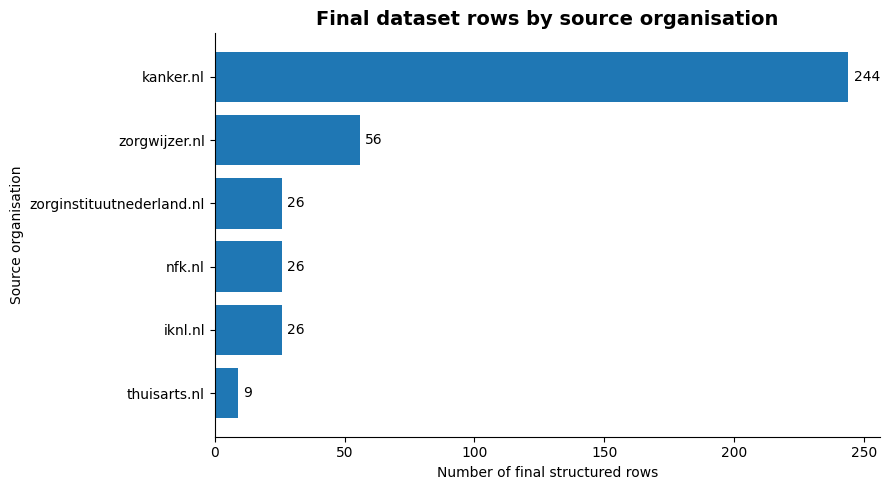

In [ ]:
# Plot final dataset rows by website/source organisation.

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    final_source_summary["source_organisation"],
    final_source_summary["final_dataset_rows"]
)

ax.set_title(
    "Final dataset rows by source organisation",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Number of final structured rows")
ax.set_ylabel("Source organisation")

# Add row-count labels to the end of each bar.
for index, value in enumerate(final_source_summary["final_dataset_rows"]):
    ax.text(
        value + 2,
        index,
        str(value),
        va="center",
        fontsize=10
    )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

In [ ]:
# ============================================================
# Visualisation: final dataset topic coverage
# ============================================================

topic_label_map = {
    "additional_support": "Additional support",
    "referrals_process": "Referrals/process",
    "treatment_decisions": "Treatment decisions",
    "communication_understanding": "Communication/understanding",
    "waiting_times": "Waiting times",
    "second_opinions": "Second opinions",
}


def split_topic_values(topic_string):
    """Split semi-colon separated topic labels into a clean list."""
    if pd.isna(topic_string):
        return []

    topics = []

    for topic in str(topic_string).split(";"):
        topic = topic.strip()

        if topic:
            topics.append(topic)

    return topics


# Split multi-topic rows so each topic instance can be counted.
final_topic_instances_df = (
    final_structured_dataset_df
    .assign(
        topic_instance=final_structured_dataset_df["chunk_topic_area"]
        .map(split_topic_values)
    )
    .explode("topic_instance")
)

final_topic_instances_df = (
    final_topic_instances_df
    .dropna(subset=["topic_instance"])
    .loc[lambda df: df["topic_instance"].astype(str).str.strip().ne("")]
)

final_topic_coverage_summary = (
    final_topic_instances_df
    .groupby("topic_instance", as_index=False)
    .agg(
        topic_instances=("chunk_id", "count"),
        unique_chunks=("chunk_id", "nunique"),
        unique_source_urls=("source_url", "nunique"),
        source_organisations=("source_organisation", "nunique")
    )
)

final_topic_coverage_summary["topic_label"] = (
    final_topic_coverage_summary["topic_instance"]
    .map(topic_label_map)
    .fillna(final_topic_coverage_summary["topic_instance"])
)

final_topic_coverage_summary = (
    final_topic_coverage_summary
    .sort_values("topic_instances", ascending=True)
)

final_topic_coverage_summary

,topic_instance,topic_instances,unique_chunks,unique_source_urls,source_organisations,topic_label
4,waiting_times,3,3,1,1,Waiting times
1,communication_understanding,39,39,25,6,Communication/understanding
3,treatment_decisions,70,70,40,5,Treatment decisions
2,referrals_process,111,111,41,6,Referrals/process
0,additional_support,250,250,77,6,Additional support


**Observation:** Final topic coverage is uneven, with `waiting_times` represented by the fewest topic instances.


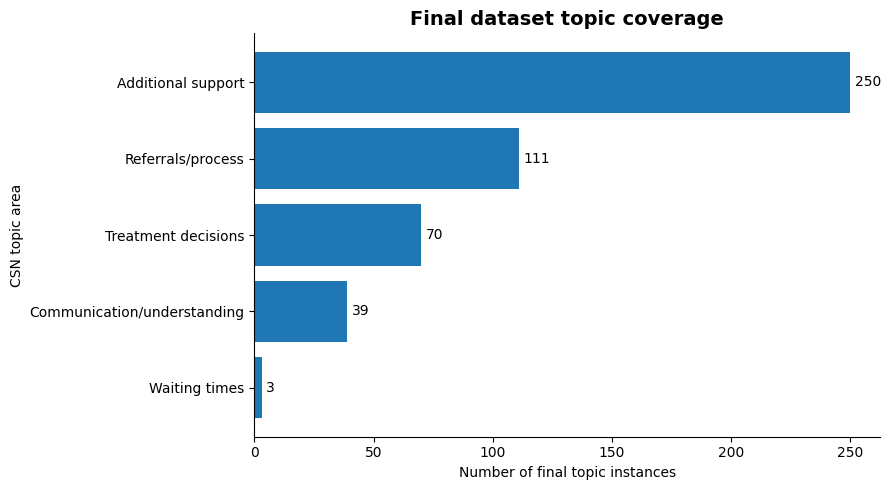

In [ ]:
# Plot final topic coverage.

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    final_topic_coverage_summary["topic_label"],
    final_topic_coverage_summary["topic_instances"]
)

ax.set_title(
    "Final dataset topic coverage",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Number of final topic instances")
ax.set_ylabel("CSN topic area")

for index, value in enumerate(final_topic_coverage_summary["topic_instances"]):
    ax.text(
        value + 2,
        index,
        str(value),
        va="center",
        fontsize=10
    )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### Summary of the final structured dataset

The final dataset provides an initial English-language knowledge base for CSN’s future Patient Navigator, created from the manually reviewed source links.

After scraping, chunking, content-based topic matching, duplicate removal and translation, the final dataset contains 388 translated text chunks from 88 unique source URLs. Each chunk keeps the original Dutch text, the English translation, the source organisation, the source URL and the scrape date. This means the information remains traceable and CSN can see when the source material was collected.

The dataset is structured around patient-navigation needs rather than just website pages. Each chunk is linked to a reviewed page topic, a content-based chunk topic, a community question and a practical next step. This makes the dataset useful for a future Patient Navigator.

The final dataset is mainly based on kanker.nl, which contributed 245 of the 388 chunks, mirroring the outcome of the manual review and the focused chunk matching process.

In terms of topic coverage, the strongest areas were additional support, referrals/process and treatment decisions. Communication/understanding was represented to a lesser extent, while waiting times and second opinions remained much less covered. This shows where future source expansion or more targeted searching could focus.

*Key figures:*  
- Final rows: 388
- Unique source URLs: 88
- Missing English translations: 0
- Missing community questions: 0

*Website counts:*
- kanker.nl chunks: 245
- zorgwijzer.nl chunks: 56
- nfk.nl chunks: 26
- iknl.nl chunks: 26
- zorginstituutnederland.nl chunks: 26
- thuisarts.nl chunks: 9

*Topic coverage:*
- Additional support: 251
- Referrals/process: 111
- Treatment decisions: 70
- Communication/understanding: 39
- Waiting times: 3
- Second opinions: 1

### Manual quality check of final structured dataset

A small manual quality check was carried out on a sample of rows from the final structured dataset, which focused on whether the content-based topic area, community question and practical next step matched the English translation of the chunk.

Overall, the dataset appeared suitable as an initial structured knowledge base. Most chunks were mapped to appropriate CSN topic areas, the English translations were broadly usable, and the practical next steps were general and navigation-focused rather than medical advice.

The check also showed some limitations. In some cases, keyword matching assigned a topic because a term appeared in the chunk, even when it was not the main focus of the text. For example, some chunks were mapped to second opinions because they stated that a service does not provide second opinions, rather than explaining how a patient can request one. Some chunks also contained remaining website navigation text, such as links, page prompts or feedback wording.

These issues do not prevent the dataset from being useful as an initial data foundation, but they show why the dataset should be treated as something CSN would need to review and refine, particularly topic labels, translations and next steps, before using the content in a live Patient Navigator.

### Limitations and future improvements

1. Initial crawl scope  
The dataset is based on a broad but controlled initial crawl. This was appropriate for creating an initial source base, but it may not have gone deep enough to capture all relevant pages, especially for waiting times and second opinions.

2. Source imbalance  
The final dataset is heavily weighted towards kanker.nl, which contributed 245 of the 388 final chunks. This is useful because kanker.nl is a trusted and relevant source, but it means the dataset is not evenly balanced across all approved websites.

3. Keyword-based topic mapping  
Topic mapping was based on keyword matching. This made the process transparent and reproducible, but it can miss relevant chunks if the wording does not match the keyword list. It can also over-assign topics where a keyword appears in a minor or negative context.

4. Residual website text  
Some website navigation text remained after scraping and cleaning. This is a common issue with web-scraped data and could be improved with more site-specific scraping rules.

5. Machine translation  
The translations were produced using the Google Cloud Translation API. The translation checks suggested the outputs were broadly complete, but the translations should still be reviewed by CSN before being used in patient-facing content. Some proper nouns, website names or healthcare terms may also need manual review.

Future improvements could include deeper targeted searches for underrepresented topics, adding additional approved sources, using more advanced classification methods, manually reviewing key translations, and developing short patient-facing summaries from the translated chunks.